# Phase-4A — TrustFin-SLM Execution Verification and Financial Grounding
**Project:** *Trustworthy Small Language Models for Financial Tasks*  
**Backbone:** Phase-3 frozen E5 (Qwen3-1.7B balanced FinQA+FiQA QLoRA)  
**Research stage:** Validation-only methodology development; **no protected test use**.

### Research questions

1. How much does **executing the generated FinQA program** improve end-answer accuracy compared with the model's generated `ANSWER:` text?
2. Which **inference-time verification signals** distinguish reliable and unreliable executed programs?
3. Can financial number grounding and program-structure checks detect erroneous reasoning **without accessing gold answers**?
4. What exact, auditable **feature contract** should Phase-4B use for calibration and abstention?

**Scientific caveat:** Executability and literal presence do **not** prove semantic program correctness. Phase-4A is a deterministic verifier and *feature-generation stage*, not a claimed end-to-end solution to semantic grounding.

### A1–A5 experiments

| Experiment | Purpose |
|:--|:--|
| A1 | Frozen E5 written-answer and executed-answer baselines |
| A2 | Independent response reconciliation; correction/rescue and regression categories |
| A3 | FinQA program grammar, operations, operands, references, constants, typed checks |
| A4 | Financial operand provenance: full original evidence when available; otherwise audited cached evidence, flagged as such |
| A5 | Risk-signal diagnostics on **calibration-fit only**; export label-separated Phase-4B interface and readiness gates |

FiQA is passed through with the **frozen `explicit_schema` inference outputs** to support the Phase-4B regression branch.

## How to run — student instructions

**Inputs.** Place the following files in the notebook's directory, or set their paths in the configuration cell:

- `Phase3_TrustFin_Deliverable.zip` — original Phase-3 experiment predictions.
- `Phase3_1_Review_Package(1).zip` — validated Phase-3.1 handoff and official re-audit.
- **Recommended for full financial evidence checks:** Phase-2.1 `validation.jsonl`, generated in `artifacts/phase2_1/datasets/`. Set `TRUSTFIN_PHASE2_VAL` to its full path.
- **Optional for independent *live* official execution:** original `evaluate.py` and the official FinQA `dev.json` (validation only). Set `TRUSTFIN_FINQA_EVALUATOR` and `TRUSTFIN_FINQA_DEV_JSON`.
- **Optional:** local E5 adapter directory, to recheck the checkpoint hashes against the Phase-3.1 manifest. Set `TRUSTFIN_E5_ADAPTER`.

**Execution:**

1. Use a Python 3 kernel. No GPU or model download is needed for *Phase-4A's saved-prediction audit*.
2. Run `RUN_MODE = 'smoke'` first (small deterministic subset). Check it produces `SMOKE PASS`.
3. Restart the kernel, change to `RUN_MODE = 'full'`, then **Run All**. Full mode audits all 883 FinQA and 117 FiQA validation records.
4. Carefully review `phase4a_readiness.json` and the evidence provenance status. A core offline PASS is not a claim that the original input or model-weight bytes were revalidated locally.
5. **Do not load FinQA/FiQA test, FinBen-FOMC or FinTrust.** Phase-4B must use the exported `phase4b_*_features.jsonl` and `phase4b_*_labels.jsonl` separately.
6. Share the executed notebook and `Phase4A_Review_Package.zip` (output list at the end).

**Modes / limitations:** The notebook still runs without Phase-2.1 `validation.jsonl`, using Phase-3.1's previously audited cached literal indicators; it marks that provenance `CACHED` and blocks a claim of **fully reproduced evidence grounding**. Supplying the original validation JSONL upgrades the audit to `RECOMPUTED`.

**Typical dependencies:** `numpy`, `pandas`, `scipy`, `scikit-learn`, `matplotlib`, `nbformat` (only used to build this notebook, not execute it). Optional `transformers` is *not* required unless separately performing an input visibility/tokenizer pilot.

## 0. Imports and configuration

In [1]:
from __future__ import annotations
import os, io, json, re, math, csv, zipfile, hashlib, shutil, sys, platform, statistics
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime, timezone
from typing import Any, Mapping, Optional, Sequence
import numpy as np
import pandas as pd
from scipy.stats import fisher_exact, spearmanr
from sklearn.metrics import roc_auc_score, average_precision_score
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------
# RUN MODE  ->  'smoke' (35 FinQA + 15 FiQA subset)  or  'full' (883 + 117)
# The smoke run has been validated (SMOKE PASS). This notebook is now pinned
# to 'full'. The env var TRUSTFIN_PHASE4A_MODE still overrides this value.
# ---------------------------------------------------------------------------
RUN_MODE = os.environ.get('TRUSTFIN_PHASE4A_MODE', 'full').strip().lower()  # smoke | full
SEED = 42

def _discover_repo(start: Path) -> Path:
    """Walk up from the launch directory until the TrustFin repo root is found."""
    for cand in [start, *start.parents]:
        if ((cand / 'artifacts' / 'phase2_1' / 'datasets' / 'validation.jsonl').is_file()
                and (cand / 'deliverables' / 'Phase3_TrustFin_Deliverable.zip').is_file()):
            return cand
    return Path('/home/heet18/Downloads/Research Papers')

REPO = Path(os.environ.get('TRUSTFIN_PHASE4A_REPO', str(_discover_repo(Path.cwd())))).expanduser()
BASE = Path(os.environ.get('TRUSTFIN_PHASE4A_INPUT_DIR', str(REPO))).expanduser()
# Smoke writes to its own root so it can never contaminate the full review package.
ROOT = Path(os.environ.get('TRUSTFIN_PHASE4A_OUTPUT',
                           str(BASE / ('artifacts/phase4a_smoke' if RUN_MODE == 'smoke' else 'artifacts/phase4a'))
                           )).expanduser()
PHASE3_ZIP = Path(os.environ.get('TRUSTFIN_PHASE3_ZIP',
                                 str(BASE / 'deliverables/Phase3_TrustFin_Deliverable.zip'))).expanduser()
PHASE3_1_ZIP = Path(os.environ.get('TRUSTFIN_PHASE3_1_ZIP',
                                   str(BASE / 'artifacts/phase3_1/Phase3_1_Review_Package.zip'))).expanduser()
# Original Phase-2.1 validation.jsonl -> upgrades evidence provenance to RECOMPUTED.
PHASE2_VAL_OVERRIDE = os.environ.get('TRUSTFIN_PHASE2_VAL',
                                      str(BASE / 'artifacts/phase2_1/datasets/validation.jsonl'))
OFFICIAL_EVALUATOR_OVERRIDE = os.environ.get('TRUSTFIN_FINQA_EVALUATOR','').strip()
FINQA_DEV_OVERRIDE = os.environ.get('TRUSTFIN_FINQA_DEV_JSON','').strip()
E5_ADAPTER_OVERRIDE = os.environ.get('TRUSTFIN_E5_ADAPTER','').strip()

assert RUN_MODE in {'smoke','full'}
for p in (PHASE3_ZIP,PHASE3_1_ZIP):
    assert p.is_file(), f'Missing ZIP: {p}. Set input path in configuration.'
for part in ['tables','analysis','features','labels','manifests','plots','phase4b_interface']:
    (ROOT/part).mkdir(parents=True, exist_ok=True)
print('Mode:',RUN_MODE)
print('Repo:',REPO)
print('Phase-3:',PHASE3_ZIP)
print('Phase-3.1:',PHASE3_1_ZIP)
print('Phase-2.1 validation:',PHASE2_VAL_OVERRIDE)
print('Output:',ROOT)


Mode: full
Repo: /Users/krishpatel/Desktop/trust_fin
Phase-3: /Users/krishpatel/Desktop/trust_fin/deliverables/Phase3_TrustFin_Deliverable.zip
Phase-3.1: /Users/krishpatel/Desktop/trust_fin/artifacts/phase3_1/Phase3_1_Review_Package.zip
Phase-2.1 validation: /Users/krishpatel/Desktop/trust_fin/artifacts/phase2_1/datasets/validation.jsonl
Output: /Users/krishpatel/Desktop/trust_fin/artifacts/phase4a


## 1. Read ZIP contents safely; verify frozen metadata and split policy

In [2]:
z3=zipfile.ZipFile(PHASE3_ZIP)
z31=zipfile.ZipFile(PHASE3_1_ZIP)
PREFIX='Phase3_TrustFin_Deliverable/artifacts/phase3/'
def file_sha(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as fh:
        for b in iter(lambda:fh.read(1024*1024),b''):h.update(b)
    return h.hexdigest()
def zip_bytes(z,name):
    if name not in z.namelist():raise FileNotFoundError(name)
    return z.read(name)
def zjson(z,name): return json.loads(zip_bytes(z,name).decode('utf-8'))
def zcsv(z,name): return pd.read_csv(io.BytesIO(zip_bytes(z,name)), low_memory=False)
def zjsonl(z,name):return [json.loads(l) for l in zip_bytes(z,name).decode('utf8').splitlines() if l.strip()]
def dump_json(path,obj):
    path=Path(path); path.parent.mkdir(exist_ok=True,parents=True)
    path.write_text(json.dumps(obj,indent=2,ensure_ascii=False,default=str),encoding='utf8')
def dump_jsonl(path,rows):
    path=Path(path);path.parent.mkdir(exist_ok=True,parents=True)
    with path.open('w',encoding='utf8') as fh:
        for r in rows: fh.write(json.dumps(r,ensure_ascii=False,default=str)+'\n')

freeze=zjson(z3,PREFIX+'manifests/phase3_freeze.json')
handoff=zjson(z31,'phase4_interface/phase4_handoff_config.json')
phase31=zjson(z31,'manifests/phase3_1_readiness.json')
assert freeze['winner']['experiment']=='E5' and handoff['frozen_experiment']=='E5'
assert freeze['winner']['model_id']=='Qwen/Qwen3-1.7B'
assert handoff['prompts']=={'FinQA':'canonical','FiQA':'explicit_schema'}
assert phase31['core_offline_audit']=='PASS'
assert handoff['protected_test_policy'].lower().find('no protected test')>=0
fingerprints={'phase3_zip_sha256':file_sha(PHASE3_ZIP),
              'phase3_1_zip_sha256':file_sha(PHASE3_1_ZIP),
              'phase3_freeze_sha256':hashlib.sha256(zip_bytes(z3,PREFIX+'manifests/phase3_freeze.json')).hexdigest(),
              'handoff_sha256':hashlib.sha256(zip_bytes(z31,'phase4_interface/phase4_handoff_config.json')).hexdigest()}
dump_json(ROOT/'manifests/input_fingerprints.json',fingerprints)
print('Frozen primary experiment: E5; original protocol preserved.')

Frozen primary experiment: E5; original protocol preserved.


## 2. Strict record reconciliation: FinQA + FiQA, frozen prompt variants

In [3]:
# Phase-3.1 audit rows and explicitly frozen prompt datasets.
a=zjsonl(z31,'phase4_interface/phase4_validation_features.jsonl')
frozen=pd.DataFrame(a)
finqa=zcsv(z3,PREFIX+'predictions/E5.csv').query('dataset=="FinQA"').copy()
fiqa=zcsv(z3,PREFIX+'predictions/E10_explicit_schema.csv').query('dataset=="FiQA"').copy()
reaudit=zcsv(z31,'analysis/official_execution_reaudit.csv')
ground_cache=zcsv(z31,'analysis/operand_grounding_audit.csv')
lengths=zcsv(z31,'analysis/exact_prompt_lengths.csv')

# All keys are validation-specific IDs; never inspect protected test sets.
for name,df in [('phase3_1 features',frozen),('FinQA frozen E5',finqa),('FiQA frozen prompt',fiqa)]:
    assert df.record_id.is_unique,(name,'duplicate record_id')
    if 'phase2_split' in df: assert set(df.phase2_split)=={'validation'}
assert len(frozen)==1000 and set(frozen.dataset)=={'FinQA','FiQA'}
assert len(finqa)==883 and len(fiqa)==117
assert set(finqa.record_id)==set(frozen.query('dataset=="FinQA"').record_id)
assert set(fiqa.record_id)==set(frozen.query('dataset=="FiQA"').record_id)
assert set(reaudit.record_id)==set(finqa.record_id)
assert set(ground_cache.record_id)==set(finqa.record_id)
assert set(lengths.record_id)==set(finqa.record_id)

# Resolve smoke cap deterministically. Full retains all 1000 examples.
if RUN_MODE=='smoke':
    sampled_f=set(sorted(finqa.record_id)[:35]);sampled_q=set(sorted(fiqa.record_id)[:15])
    finqa=finqa[finqa.record_id.isin(sampled_f)].copy()
    fiqa=fiqa[fiqa.record_id.isin(sampled_q)].copy()
    frozen=frozen[frozen.record_id.isin(sampled_f|sampled_q)].copy()
    reaudit=reaudit[reaudit.record_id.isin(sampled_f)].copy()
    ground_cache=ground_cache[ground_cache.record_id.isin(sampled_f)].copy()
    lengths=lengths[lengths.record_id.isin(sampled_f)].copy()

assert finqa.record_id.is_unique and fiqa.record_id.is_unique
assert not(set(finqa.record_id)&set(fiqa.record_id))
assert set(frozen.calibration_fold)=={'calibration_fit','calibration_holdout'} or RUN_MODE=='smoke'
print('FinQA:',len(finqa),'FiQA:',len(fiqa))
print('Frozen confidence and calibration records:',len(frozen))

FinQA: 883 FiQA: 117
Frozen confidence and calibration records: 1000


## 3. Utility validators, label isolation, and program grammar

In [4]:
TRUE={'1','true','yes','t'}
def as_bool(x):
    if isinstance(x,(bool,np.bool_)):return bool(x)
    if pd.isna(x):return False
    if isinstance(x,(int,float,np.number)):return bool(x) if np.isfinite(x) else False
    return str(x).strip().lower() in TRUE

def safe_num(x):
    try:
        if x is None or pd.isna(x):return None
        t=str(x).strip().replace(',','').replace('$','')
        if not t:return None
        pct=t.endswith('%')
        if pct:t=t[:-1]
        n=float(t)
        return n/100.0 if pct else n
    except Exception:return None

def near_equal(x,y,atol=1e-4,rtol=1e-3):
    if str(x).strip().lower()==str(y).strip().lower():return True
    a,b=safe_num(x),safe_num(y)
    return a is not None and b is not None and bool(np.isclose(a,b,atol=atol,rtol=rtol))

VALID_OPERATIONS={'add','subtract','multiply','divide','greater','exp',
                  'table_sum','table_average','table_max','table_min'}
# String-level structure validation, not a replacement for official eval_program.
ATOM_RE=re.compile(r'^(?:#\d+|const_[-+]?\d+(?:\.\d+)?|[-+]?(?:\d+(?:\.\d+)?|\.\d+)%?)$',re.I)
STEP_RE=re.compile(r'^([A-Za-z_][A-Za-z_0-9]*)\s*\((.*)\)$',re.S)
LITERAL_RE=re.compile(r'^[-+]?(?:\d+(?:\.\d+)?|\.\d+)%?$')
CONST_RE=re.compile(r'^const_[-+]?\d+(?:\.\d+)?$',re.I)
REF_RE=re.compile(r'^#(\d+)$')

def split_top_level(s:str,delimiter=','):
    chunks=[];start=0;level=0
    for i,ch in enumerate(s):
        if ch=='(':level+=1
        elif ch==')':level-=1
        elif ch==delimiter and level==0:
            chunks.append(s[start:i].strip());start=i+1
        if level<0: return None
    if level!=0:return None
    chunks.append(s[start:].strip())
    return chunks

def parse_steps(program):
    if not isinstance(program,str) or not program.strip():
        return [],['missing_program']
    parts=split_top_level(program)
    if not parts:return [],['unbalanced_parentheses']
    steps=[];issues=[]
    for i,part in enumerate(parts):
        match=STEP_RE.fullmatch(part)
        if not match:
            issues.append('step_syntax');continue
        op=match.group(1).lower();args=split_top_level(match.group(2))
        if not args or len(args)==0 or any(not x for x in args):
            issues.append('arguments_syntax');continue
        # Official FinQA table operators accept a text column name and often `none`.
        # Treating those as numerical operands would falsely reject valid programs.
        if op not in VALID_OPERATIONS:issues.append('unknown_operator')
        if op in {'add','subtract','multiply','divide','greater','exp'} and len(args)!=2:
            issues.append('arithmetic_arity')
        if op.startswith('table_') and len(args)!=2:issues.append('table_arity')
        for arg in args:
            if op.startswith('table_'):
                if not arg.strip():issues.append('empty_table_operand')
            else:
                if not ATOM_RE.fullmatch(arg):issues.append('unsupported_operand_token')
                m=REF_RE.fullmatch(arg)
                if m and int(m.group(1))>=i:issues.append('invalid_forward_reference')
        if op=='divide' and len(args)==2 and safe_num(args[1])==0:
            issues.append('literal_zero_denominator')
        steps.append({'step':i,'operator':op,'arguments':args})
    return steps,sorted(set(issues))

def program_features(p):
    steps,issues=parse_steps(p)
    args=[x for s in steps for x in s['arguments']]
    literals=[x for x in args if LITERAL_RE.fullmatch(x)]
    ops=[s['operator'] for s in steps]
    refs=[x for x in args if REF_RE.fullmatch(x)]
    return {
        'program_step_count':len(steps),
        'program_operator_count':len(ops),
        'program_operators':'|'.join(ops),  # descriptive, not a numeric risk input
        'program_operand_count':len(args),
        'program_literal_count':len(literals),
        'program_reference_count':len(refs),
        'program_const_count':sum(bool(CONST_RE.fullmatch(x)) for x in args),
        'has_division':int('divide' in ops),
        'has_table_operation':int(any(x.startswith('table_') for x in ops)),
        'has_comparison':int('greater' in ops),
        'program_structural_valid':int(len(issues)==0 and len(steps)>0),
        'issue_count':len(issues),
        'issues':issues,
    }

# Minimal unit tests — no dependence on evaluation labels.
assert parse_steps('divide(637, 5.0)')[1]==[]
assert parse_steps('add(2, 3), divide(#0, const_100)')[1]==[]
assert 'invalid_forward_reference' in parse_steps('add(#0,3)')[1]
assert 'unsupported_operand_token' in parse_steps('divide(20ac750,2)')[1]
assert 'literal_zero_denominator' in parse_steps('divide(2,0)')[1]
assert parse_steps('table_average(net sales, none)')[1]==[]
assert 'table_arity' in parse_steps('table_average(205,163,110)')[1]
print('Grammar tests PASS')

Grammar tests PASS


## 4. Optional original evidence loading (recomputation versus cached auditing)

The original **Phase-2.1 validation only** file is recommended. We explicitly refuse paths containing common protected-test tokens. A record may contain gold fields, but only its `input`/`instruction` fields are used in *feature engineering*.

If unavailable, we retain Phase-3.1's unmatched-literal indicator as a **cached historical feature**, with a provenance flag and conditional readiness.

In [5]:
def find_val_file():
    cand=[]
    if PHASE2_VAL_OVERRIDE:cand.append(Path(PHASE2_VAL_OVERRIDE))
    # Common local locations, without scanning the whole home directory.
    cand.extend([
        BASE/'artifacts/phase2_1/datasets/validation.jsonl',
        BASE/'phase2_1/datasets/validation.jsonl',
        BASE/'validation.jsonl',
        BASE.parent/'artifacts/phase2_1/datasets/validation.jsonl',
    ])
    for p in cand:
        if p.is_file() and not any(k in p.name.lower() for k in ['test','protected','fintrust','fomc']):
            return p.resolve()
    return None

VAL_FILE=find_val_file(); ORIGINAL={}
if VAL_FILE:
    records=[json.loads(line) for line in VAL_FILE.read_text(encoding='utf8').splitlines() if line.strip()]
    assert len(records)==1000,'Phase-2.1 validation should have exactly 1,000 rows.'
    assert {r['dataset'] for r in records}=={'FinQA','FiQA'}
    assert len({r['record_id'] for r in records})==1000
    ORIGINAL={r['record_id']:r for r in records}
    assert set(frozen.record_id).issubset(ORIGINAL)
    # Phase-2.1 validation export: FinQA rows carry split='dev', FiQA rows carry
    # split='valid' (FiQA's official HF validation split). Both are validation
    # splits; every test/protected/FOMC/FinTrust token remains rejected.
    assert all(str(ORIGINAL[k]['split']).lower() in {'dev','valid','validation'} for k in frozen.record_id)
    EVIDENCE_PROVENANCE='RECOMPUTED_FROM_PHASE2_1_VALIDATION'
else:
    EVIDENCE_PROVENANCE='CACHED_PHASE3_1_ONLY'
print('Validation source:',str(VAL_FILE) if VAL_FILE else 'NOT MOUNTED')
print('Evidence provenance:',EVIDENCE_PROVENANCE)

Validation source: /Users/krishpatel/Desktop/trust_fin/artifacts/phase2_1/datasets/validation.jsonl
Evidence provenance: RECOMPUTED_FROM_PHASE2_1_VALIDATION


## 5. A1/A2 — Execution baseline and non-oracle reconciliation

In [6]:
finqa=finqa.merge(frozen[['record_id','calibration_fold','sequence_likelihood_score','frozen_prompt_variant','unmatched_literal_count_in_full_input']],on='record_id',how='left',validate='one_to_one')
finqa=finqa.merge(reaudit[['record_id','official_executable','official_result','match_saved']],on='record_id',how='left',validate='one_to_one')
finqa=finqa.merge(ground_cache[['record_id','unmatched_literals']],on='record_id',how='left',validate='one_to_one')
finqa=finqa.merge(lengths[['record_id']+[c for c in ['untruncated_tokens','was_truncated','prompt_tokens_untruncated','truncated'] if c in lengths.columns]],on='record_id',how='left',validate='one_to_one')

assert finqa['match_saved'].map(as_bool).all(), 'Saved execution disagrees with official Phase3.1 re-audit.'
finqa['written_correct']=finqa.answer_correct.map(as_bool)
finqa['exec_correct']=finqa.execution_correct.map(as_bool)
finqa['is_executable']=finqa.program_executable.map(as_bool)
finqa['answer_agrees_with_execution']=[near_equal(a,b) if ok else False for a,b,ok in zip(finqa.pred_answer,finqa.executed_answer,finqa.is_executable)]
finqa['corrected_answer']=finqa.apply(lambda r: r.executed_answer if r.is_executable else r.pred_answer,axis=1)
finqa['corrected_correct']=[near_equal(p,g) for p,g in zip(finqa.corrected_answer,finqa.gold_answer)]
finqa['reconciliation_category']=np.select([
    finqa.written_correct & finqa.exec_correct,
    ~finqa.written_correct & finqa.exec_correct,
    finqa.written_correct & ~finqa.exec_correct,
],[ 'both_correct','execution_only_correct','written_only_correct'],default='both_wrong')

A1_A2={
    'n':int(len(finqa)),
    'written_answer_accuracy':float(finqa.written_correct.mean()),
    'executed_program_answer_accuracy':float(finqa.exec_correct.mean()),
    'corrected_output_accuracy':float(finqa.corrected_correct.mean()),
    'execution_validity':float(finqa.is_executable.mean()),
    'answer_execution_agreement':float(finqa.answer_agrees_with_execution.mean()),
    'execution_minus_written_gain_pp':float(100*(finqa.exec_correct.mean()-finqa.written_correct.mean())),
    'reconciliation_outcomes':{k:int(v) for k,v in finqa.reconciliation_category.value_counts().items()},
}
dump_json(ROOT/'analysis/A1_A2_reconciliation.json',A1_A2)
print(json.dumps(A1_A2,indent=2))

{
  "n": 883,
  "written_answer_accuracy": 0.37599093997734995,
  "executed_program_answer_accuracy": 0.6749716874292185,
  "corrected_output_accuracy": 0.6749716874292185,
  "execution_validity": 0.9966024915062288,
  "answer_execution_agreement": 0.5639864099660249,
  "execution_minus_written_gain_pp": 29.898074745186857,
  "reconciliation_outcomes": {
    "both_correct": 331,
    "both_wrong": 286,
    "execution_only_correct": 265,
    "written_only_correct": 1
  }
}


## 6. A3 — Program structural/typed validation and error categories

In [7]:
pfields=pd.DataFrame([{'record_id':r.record_id,**program_features(r.pred_program)} for r in finqa.itertuples(index=False)])
assert pfields.record_id.is_unique
finqa=finqa.merge(pfields,on='record_id',validate='one_to_one')
struct_cases=[]
for r in finqa.itertuples(index=False):
    struct_cases.append({
        'record_id':r.record_id,'program_step_count':r.program_step_count,
        'program_operators':r.program_operators,'program_structural_valid':r.program_structural_valid,
        'issues':'|'.join(r.issues),'program_executable':r.is_executable,
        'execution_correct_validation_label':r.exec_correct,
    })
struct_df=pd.DataFrame(struct_cases)
struct_df.to_csv(ROOT/'analysis/A3_program_structure_cases.csv',index=False)
A3={
 'n':len(struct_df),
 'structural_valid_n':int(struct_df.program_structural_valid.sum()),
 'program_executable_n':int(struct_df.program_executable.sum()),
 'issue_counts':dict(Counter(i for arr in finqa.issues for i in arr)),
 'step_count_distribution':{str(k):int(v) for k,v in finqa.program_step_count.value_counts().sort_index().items()},
 'mismatch_structural_to_official':int((finqa.program_structural_valid.astype(bool)!=finqa.is_executable).sum()),
 'caution':'Structural grammar is an additional verifier feature; the official executor remains authoritative.'
}
dump_json(ROOT/'analysis/A3_program_structure_summary.json',A3)
print(json.dumps(A3,indent=2))

{
  "n": 883,
  "structural_valid_n": 880,
  "program_executable_n": 880,
  "issue_counts": {
    "unsupported_operand_token": 2,
    "table_arity": 1
  },
  "step_count_distribution": {
    "1": 559,
    "2": 267,
    "3": 32,
    "4": 4,
    "5": 19,
    "6": 1,
    "7": 1
  },
  "mismatch_structural_to_official": 0,
  "caution": "Structural grammar is an additional verifier feature; the official executor remains authoritative."
}


## 7. A4 — Evidence-aware literal provenance (non-oracle)

The default exact-token matcher tests whether each **numeric operand literal** appears in the supplied original Phase-2.1 `input` (financial text/table/question). It excludes FinQA constants (`const_100`) and intermediate references (`#0`). It also reports where each supported literal appears. **No gold program or gold answer is consulted.**

A *document-wide match* is not proof of question-specific numerical grounding. To avoid false semantic claims, we call it `literal_presence`, not `semantic_grounded`.

In [8]:
NUMBER_TOKEN_RE=re.compile(r'(?<![\w#])[-+]?(?:\d[\d,]*(?:\.\d+)?|\.\d+)%?(?![\w])')
STOPWORDS={'the','and','of','to','was','is','in','for','as','at','on','by','from','which','what','how','many','much','an','a','with','its','were','during','year','total','percentage','percent','amount','did','change','between','company','would','that','this'}
WORD_RE=re.compile(r'[A-Za-z]{3,}')

def number_normal_form(x):
    s=str(x).strip().replace(',','').replace('$','')
    try:
        pct=s.endswith('%'); v=float(s[:-1] if pct else s)
        return f'{v:.10g}',pct
    except Exception:return s,False

def numeric_in_text(literal,text):
    norm,pct=number_normal_form(literal)
    for m in NUMBER_TOKEN_RE.finditer(str(text)):
        nn,npct=number_normal_form(m.group())
        if nn==norm and npct==pct:return True
        # FinQA may write 12% and input may represent 12 without '%' symbol;
        # do not implicitly equate these without explicit percent context.
    return False

def split_evidence(text):
    s=str(text or '')
    m=re.search(r'Financial text:\s*(.*?)\s*Financial table:\s*(.*?)\s*Question:\s*(.*)$',s,re.I|re.S)
    if m:return {'narrative':m.group(1),'table':m.group(2),'question':m.group(3)}
    return {'narrative':s,'table':'','question':''}

def overlap_strength(question,nearby):
    q={w.lower() for w in WORD_RE.findall(question) if w.lower() not in STOPWORDS}
    c={w.lower() for w in WORD_RE.findall(nearby) if w.lower() not in STOPWORDS}
    return len(q&c)/max(1,len(q))

def financial_evidence_features(program,input_text):
    steps,_=parse_steps(program)
    literals=[a for step in steps for a in step['arguments'] if LITERAL_RE.fullmatch(a)]
    sources=split_evidence(input_text)
    matches=[]
    for literal in literals:
        contexts=[];best_overlap=0.0
        for source,txt in sources.items():
            if numeric_in_text(literal,txt):
                contexts.append(source)
                # Relevance is a local lexical heuristic, not semantic validation.
                for m in NUMBER_TOKEN_RE.finditer(txt):
                    if number_normal_form(m.group())==number_normal_form(literal):
                        window=txt[max(0,m.start()-90):m.end()+90]
                        best_overlap=max(best_overlap,overlap_strength(sources['question'],window))
        matches.append({'literal':literal,'sources':contexts,'question_local_overlap':best_overlap})
    missing=[x['literal'] for x in matches if not x['sources']]
    supported=len(matches)-len(missing)
    return {
        'literal_count':len(matches),
        'unmatched_literal_count':len(missing),
        'literal_presence_fraction':supported/len(matches) if matches else 1.0,
        'any_literal_unmatched':int(bool(missing)),
        'literal_in_table_count':sum('table' in x['sources'] for x in matches),
        'literal_in_narrative_count':sum('narrative' in x['sources'] for x in matches),
        'literal_in_question_count':sum('question' in x['sources'] for x in matches),
        'max_question_local_overlap':max((x['question_local_overlap'] for x in matches),default=0.0),
        'missing_literals':missing,
        'literal_source_matches':matches,
    }

assert numeric_in_text('637','637 million')
assert not numeric_in_text('637','1637 million')
assert numeric_in_text('12%','revenue 12%')
assert not numeric_in_text('12%','revenue 12 in 2020')

finqa_evidence_rows=[]
for r in finqa.itertuples(index=False):
    if r.record_id in ORIGINAL:
        evidence=financial_evidence_features(r.pred_program,ORIGINAL[r.record_id]['input'])
        prov='RECOMPUTED_FULL_ORIGINAL_VALIDATION'
    else:
        v=r.unmatched_literal_count_in_full_input
        unmatched=0 if pd.isna(v) else int(v)
        evidence={
            'literal_count':int(r.program_literal_count),
            'unmatched_literal_count':unmatched,
            'literal_presence_fraction':max(0,1-unmatched/max(int(r.program_literal_count),1)),
            'any_literal_unmatched':int(unmatched>0),
            'literal_in_table_count':None,
            'literal_in_narrative_count':None,
            'literal_in_question_count':None,
            'max_question_local_overlap':None,
            'missing_literals':[],
            'literal_source_matches':[],
        }
        prov='CACHED_PHASE3_1_HEURISTIC'
    finqa_evidence_rows.append({'record_id':r.record_id,'evidence_provenance':prov,**evidence})
evidence_df=pd.DataFrame(finqa_evidence_rows)
assert evidence_df.record_id.is_unique
finqa=finqa.merge(evidence_df.drop(columns=['missing_literals','literal_source_matches']),on='record_id',validate='one_to_one')
evidence_df.to_csv(ROOT/'analysis/A4_operand_evidence_cases.csv',index=False)
A4={
 'n':len(evidence_df),
 'evidence_provenance':EVIDENCE_PROVENANCE,
 'unmatched_any_n':int(evidence_df.any_literal_unmatched.sum()),
 'unmatched_literals_total':int(evidence_df.unmatched_literal_count.sum()),
 'document_literal_presence_is_not_semantic_grounding':True,
 'original_input_recomputed':bool(ORIGINAL),
}
dump_json(ROOT/'analysis/A4_operand_evidence_summary.json',A4)
print(json.dumps(A4,indent=2))

{
  "n": 883,
  "evidence_provenance": "RECOMPUTED_FROM_PHASE2_1_VALIDATION",
  "unmatched_any_n": 21,
  "unmatched_literals_total": 30,
  "document_literal_presence_is_not_semantic_grounding": true,
  "original_input_recomputed": true
}


## 8. Optional live FinQA re-execution and optional E5 checkpoint hash confirmation

In [9]:
# Phase-3.1 already independently re-executed 883 saved programs, with zero mismatches.
# This optional cell performs a NEW local re-execution if the files are provided.
LIVE_EXEC={'status':'NOT_RUN','reason':'Original official evaluator and FinQA validation dev.json not supplied.'}
if OFFICIAL_EVALUATOR_OVERRIDE and FINQA_DEV_OVERRIDE:
    import importlib.util
    ep=Path(OFFICIAL_EVALUATOR_OVERRIDE);dp=Path(FINQA_DEV_OVERRIDE)
    assert ep.is_file() and dp.is_file()
    module_spec=importlib.util.spec_from_file_location('trustfin_finqa_eval_phase4a',str(ep))
    mod=importlib.util.module_from_spec(module_spec);module_spec.loader.exec_module(mod)
    raw=json.loads(dp.read_text(encoding='utf8'))
    tables={str(item['id']):item['table'] for item in raw}
    assert len(tables)==883
    mismatches=[]
    for r in finqa.itertuples(index=False):
        try:
            invalid,res=mod.eval_program(mod.program_tokenization(r.pred_program),tables[str(r.source_id)])
            valid=int(invalid)==0
        except Exception:valid,res=False,None
        if valid!=bool(r.is_executable) or (valid and not near_equal(res,r.executed_answer)):
            mismatches.append(r.record_id)
    LIVE_EXEC={'status':'PASS' if len(mismatches)==0 else 'FAIL',
               'n':len(finqa),'mismatch_count':len(mismatches),
               'evaluator_sha256':file_sha(ep),'dev_sha256':file_sha(dp),
               'mismatch_examples':mismatches[:12]}

ADAPTER_CHECK={'status':'NOT_AVAILABLE_LOCALLY','reason':'E5 adapter not present. Prior Phase-3.1 manifest retains fingerprint.'}
if E5_ADAPTER_OVERRIDE and Path(E5_ADAPTER_OVERRIDE).is_dir():
    adapter_path=Path(E5_ADAPTER_OVERRIDE)
    expected={i['relative_path']:i['sha256'] for i in handoff.get('adapter_sha256_files',[])}
    checked={key:file_sha(adapter_path/key) if (adapter_path/key).is_file() else None for key in expected}
    mismatches=[k for k in expected if checked[k]!=expected[k]]
    ADAPTER_CHECK={'status':'PASS' if not mismatches else 'FAIL',
                   'files_checked':len(checked),'mismatches':mismatches,
                   'adapter_path':str(adapter_path.resolve())}
dump_json(ROOT/'manifests/live_evaluator_status.json',LIVE_EXEC)
dump_json(ROOT/'manifests/adapter_verification_status.json',ADAPTER_CHECK)
print('Live official evaluator:',LIVE_EXEC)
print('Local E5 adapter:',ADAPTER_CHECK)

Live official evaluator: {'status': 'NOT_RUN', 'reason': 'Original official evaluator and FinQA validation dev.json not supplied.'}
Local E5 adapter: {'status': 'NOT_AVAILABLE_LOCALLY', 'reason': 'E5 adapter not present. Prior Phase-3.1 manifest retains fingerprint.'}


## 9. Construct a label-safe Phase-4B feature interface

In [10]:
# Features below must be computable at inference. Never use record_id, source_id,
# calibration_fold, gold_* fields, execution_correct, or any target-derived error as predictors.
finqa['parse_ok']=finqa.parse_success.map(as_bool).astype(int)
finqa['official_executable_feature']=finqa.is_executable.astype(int)
finqa['answer_execution_agreement_feature']=finqa.answer_agrees_with_execution.astype(int)
finqa['prompt_truncation_observed']=finqa.prompt_tokens.fillna(0).astype(int).ge(1024).astype(int)
finqa['source_likelihood']=pd.to_numeric(finqa.sequence_likelihood_score,errors='coerce')
finqa['mean_token_logprob']=pd.to_numeric(finqa.mean_logprob,errors='coerce')

FINQA_FEATURE_NAMES=[
    'source_likelihood','mean_token_logprob','generated_tokens','prompt_tokens',
    'prompt_truncation_observed','parse_ok','official_executable_feature',
    'answer_execution_agreement_feature','program_step_count','program_operand_count',
    'program_literal_count','program_reference_count','program_const_count','has_division',
    'has_table_operation','has_comparison','program_structural_valid','issue_count',
    'unmatched_literal_count','literal_presence_fraction','any_literal_unmatched',
]
OPTIONAL_ORIGINAL_ONLY=['literal_in_table_count','literal_in_narrative_count',
                        'literal_in_question_count','max_question_local_overlap']
if ORIGINAL:FINQA_FEATURE_NAMES+=OPTIONAL_ORIGINAL_ONLY

# Copy frozen *FiQA explicit-schema* scores and likelihoods; no oracle features.
fiqa=fiqa.merge(frozen[['record_id','calibration_fold','sequence_likelihood_score','frozen_prompt_variant']],on='record_id',validate='one_to_one')
fiqa['parse_ok']=fiqa.parse_success.map(as_bool).astype(int)
fiqa['source_likelihood']=pd.to_numeric(fiqa.sequence_likelihood_score,errors='coerce')
fiqa['mean_token_logprob']=pd.to_numeric(fiqa.mean_logprob,errors='coerce')
fiqa['sentiment_pred_clipped']=pd.to_numeric(fiqa.pred_score,errors='coerce').clip(-1,1)
fiqa['score_near_boundary']=(fiqa.sentiment_pred_clipped.abs()>0.9).astype(int)
FIQA_FEATURE_NAMES=['source_likelihood','mean_token_logprob','generated_tokens',
                    'prompt_tokens','parse_ok','sentiment_pred_clipped','score_near_boundary']

# Explicitly separate targets so accidental label leakage is less likely.
def feature_rows(df,feature_list,task):
    out=[]
    for r in df.to_dict(orient='records'):
        d={'record_id':r['record_id'],'dataset':task,'calibration_fold':r['calibration_fold']}
        for k in feature_list:
            v=r.get(k)
            d[k]=None if v is None or (isinstance(v,float) and not np.isfinite(v)) else v
        out.append(d)
    return out

finqa_features=feature_rows(finqa,FINQA_FEATURE_NAMES,'FinQA')
fiqa_features=feature_rows(fiqa,FIQA_FEATURE_NAMES,'FiQA')
finqa_labels=[{'record_id':r.record_id,'calibration_fold':r.calibration_fold,
              'execution_correct':bool(r.exec_correct),'written_correct':bool(r.written_correct),
              'corrected_correct':bool(r.corrected_correct)} for r in finqa.itertuples(index=False)]
fiqa_labels=[{'record_id':r.record_id,'calibration_fold':r.calibration_fold,
             'gold_sentiment':float(r.gold_score),
             'absolute_error':None if pd.isna(r.pred_score) else float(abs(float(r.pred_score)-float(r.gold_score)))} for r in fiqa.itertuples(index=False)]

for name,items in [('finqa_features',finqa_features),('fiqa_features',fiqa_features)]:
    prohibited={'execution_correct','written_correct','corrected_correct','gold_sentiment',
                'absolute_error','gold_answer','gold_program','execution_correct_validation_label',
                'source_id','target_answer','pred_answer','reconciliation_category'}
    assert all(not set(x).intersection(prohibited) for x in items),f'Label leakage detected: {name}'

for stem,rows in [('phase4b_finqa_features',finqa_features),('phase4b_fiqa_features',fiqa_features)]:
    dump_jsonl(ROOT/'phase4b_interface'/f'{stem}.jsonl',rows)
for stem,rows in [('phase4b_finqa_labels',finqa_labels),('phase4b_fiqa_labels',fiqa_labels)]:
    dump_jsonl(ROOT/'labels'/f'{stem}.jsonl',rows)

print('FinQA feature rows:',len(finqa_features),'; features:',len(FINQA_FEATURE_NAMES))
print('FiQA feature rows:',len(fiqa_features),'; features:',len(FIQA_FEATURE_NAMES))

FinQA feature rows: 883 ; features: 25
FiQA feature rows: 117 ; features: 7


## 10. A5 — Candidate risk-signal diagnostics (**calibration-fit only**)

We quantify the association between a **predeclared feature set** and FinQA execution correctness. The calibration holdout labels are intentionally **not inspected** here. Phase-4B should evaluate its selected risk estimator on that untouched holdout. All AUC values are exploratory.

The direct executable-answer baseline is 67.5% overall; Phase-4B should compare selective prediction against that baseline, not solely the much weaker written-answer accuracy.

In [11]:
# Protected holdout labels are NOT accessed here.
fit_f=finqa.query('calibration_fold=="calibration_fit"').copy()
assert len(fit_f)>0
labels=fit_f.exec_correct.astype(int).to_numpy()
feature_diagnostics=[]
CANDIDATES=['source_likelihood','generated_tokens','prompt_tokens','prompt_truncation_observed',
 'answer_execution_agreement_feature','program_step_count','program_literal_count',
 'program_reference_count','has_division','has_table_operation','program_structural_valid',
 'issue_count','unmatched_literal_count','literal_presence_fraction','any_literal_unmatched']
if ORIGINAL:CANDIDATES+=['literal_in_table_count','max_question_local_overlap']
for name in CANDIDATES:
    vals=pd.to_numeric(fit_f[name],errors='coerce')
    ok=vals.notna().to_numpy()
    v=vals.to_numpy(dtype=float)[ok];y=labels[ok]
    if len(v)<12 or np.unique(v).size<2 or np.unique(y).size<2:
        auc=float('nan');r=float('nan')
    else:
        auc=float(roc_auc_score(y,v))
        r=float(spearmanr(v,y).statistic)
    feature_diagnostics.append({
        'feature':name,'n':int(len(v)),'unique_values':int(np.unique(v).size),
        'positive_class_rate':float(np.mean(y)) if len(y) else None,
        'roc_auc_correctness_as_is':auc,
        'roc_auc_discrimination_symmetric':max(auc,1-auc) if np.isfinite(auc) else float('nan'),
        'spearman_with_execution_correctness':r,
        'fit_only':True,
    })
A5_DF=pd.DataFrame(feature_diagnostics).sort_values('roc_auc_discrimination_symmetric',ascending=False,na_position='last')
A5_DF.to_csv(ROOT/'tables/A5_fit_feature_diagnostics.csv',index=False)
print('FIT ONLY:',len(fit_f),'FinQA calibration-fit records; holdout labels not opened.')
display(A5_DF)

FIT ONLY: 698 FinQA calibration-fit records; holdout labels not opened.


,feature,n,unique_values,positive_class_rate,roc_auc_correctness_as_is,roc_auc_discrimination_symmetric,spearman_with_execution_correctness,fit_only
0,source_likelihood,698,694,0.681948,0.584507,0.584507,0.136335,True
16,max_question_local_overlap,698,58,0.681948,0.575559,0.575559,0.122254,True
15,literal_in_table_count,698,7,0.681948,0.544633,0.544633,0.076505,True
2,prompt_tokens,698,227,0.681948,0.459824,0.540176,-0.070015,True
3,prompt_truncation_observed,698,2,0.681948,0.460661,0.539339,-0.073360,True
13,literal_presence_fraction,698,5,0.681948,0.529535,0.529535,0.183806,True
12,unmatched_literal_count,698,3,0.681948,0.470503,0.529497,-0.183572,True
14,any_literal_unmatched,698,2,0.681948,0.470569,0.529431,-0.183172,True
8,has_division,698,2,0.681948,0.523658,0.523658,0.048246,True
9,has_table_operation,698,2,0.681948,0.515453,0.515453,0.084262,True


## 11. Cross-check verification flags without using gold labels as risk inputs

In [12]:
# Aggregate diagnostic rates only; these labels are used for retrospective evaluation,
# never passed through the Phase-4B inference feature interface.
FIT_GROUPS=[]
for feature in ['official_executable_feature','program_structural_valid',
                'any_literal_unmatched','answer_execution_agreement_feature',
                'prompt_truncation_observed','has_division','has_table_operation']:
    for val,g in fit_f.groupby(feature,dropna=False):
        FIT_GROUPS.append({'feature':feature,'feature_value':str(val),
                           'n':len(g),'execution_correct_n':int(g.exec_correct.sum()),
                           'execution_accuracy':float(g.exec_correct.mean())})
FIT_GROUP_DF=pd.DataFrame(FIT_GROUPS)
FIT_GROUP_DF.to_csv(ROOT/'tables/A5_fit_subgroup_accuracy.csv',index=False)
display(FIT_GROUP_DF)

,feature,feature_value,n,execution_correct_n,execution_accuracy
0,official_executable_feature,0,2,0,0.000000
1,official_executable_feature,1,696,476,0.683908
2,program_structural_valid,0,2,0,0.000000
3,program_structural_valid,1,696,476,0.683908
4,any_literal_unmatched,0,682,474,0.695015
5,any_literal_unmatched,1,16,2,0.125000
6,answer_execution_agreement_feature,0,305,208,0.681967
7,answer_execution_agreement_feature,1,393,268,0.681934
8,prompt_truncation_observed,0,333,239,0.717718
9,prompt_truncation_observed,1,365,237,0.649315


## 12. Phase-4B feature finalization and readiness gates

In [13]:
# Pre-registered shortlist: inference-time, low-dimensional, reproducible features.
# A5 associations inform interpretation, but the holdout is NOT used to pick features.
# Minimal primary-risk model: preselect without consulting holdout outcomes.
# The fit-only diagnostics show source likelihood AUC≈0.585, while program length,
# references and answer/execution agreement are weak. Keep those as ablations.
P4B_FINQA_CORE=['source_likelihood','prompt_tokens','prompt_truncation_observed']
P4B_FINQA_HARD_REJECT=['official_executable_feature','program_structural_valid']
P4B_FINQA_ABLATION=['generated_tokens','program_step_count','program_literal_count',
                    'program_reference_count','has_division','has_table_operation',
                    'answer_execution_agreement_feature']
P4B_FINQA_GROUNDING=['any_literal_unmatched','unmatched_literal_count','literal_presence_fraction']
P4B_FINQA_OPTIONAL=['literal_in_table_count','max_question_local_overlap'] if ORIGINAL else []
P4B_FIQA_CORE=['source_likelihood','generated_tokens','prompt_tokens',
              'sentiment_pred_clipped','score_near_boundary','parse_ok']

assert set(P4B_FINQA_CORE+P4B_FINQA_HARD_REJECT+P4B_FINQA_ABLATION+P4B_FINQA_GROUNDING+P4B_FINQA_OPTIONAL).issubset(FINQA_FEATURE_NAMES)
assert set(P4B_FIQA_CORE).issubset(FIQA_FEATURE_NAMES)
# Label columns are in entirely different files, and model features cannot depend on gold.

FEATURE_POLICY={
 'schema_version':'trustfin.phase4a.v1',
 'phase3_frozen_backbone':'E5',
 'primary_model':'Qwen/Qwen3-1.7B',
 'validation_only':True,
 'fit_split':'calibration_fit',
 'holdout_split':'calibration_holdout',
 'forbidden_feature_names':['record_id','source_id','calibration_fold','gold_program',
  'gold_answer','gold_sentiment','absolute_error','execution_correct','written_correct',
  'corrected_correct','execution_correct_validation_label','program_exact_match_validation_label'],
 'FinQA':{
   'core_features':P4B_FINQA_CORE,
   'deterministic_rejection_gates':P4B_FINQA_HARD_REJECT,
   'ablation_only_features':P4B_FINQA_ABLATION,
   'grounding_features_conditional_on_recomputation':P4B_FINQA_GROUNDING,
   'optional_full_evidence_features':P4B_FINQA_OPTIONAL,
   'fit_only_findings':{
       'source_likelihood_AUC_correctness':float(A5_DF.set_index('feature').loc['source_likelihood','roc_auc_correctness_as_is']),
       'unmatched_literal_error_rate_fit':(
           float(1-FIT_GROUP_DF[(FIT_GROUP_DF.feature=='any_literal_unmatched')&(FIT_GROUP_DF.feature_value=='1')].execution_accuracy.iloc[0])
           if len(FIT_GROUP_DF[(FIT_GROUP_DF.feature=='any_literal_unmatched')&(FIT_GROUP_DF.feature_value=='1')])
           else None
       ),
       'agreement_is_weak_risk_predictor':True,
   },
   'target':'execution_correct',
   'recommended_baselines':['raw_token_confidence','execution_only','execution_plus_heuristic',
                            'simple_logistic_risk_calibrator'],
   'caution':'Do not claim logical/semantic correctness from numeric presence or answer-program agreement.'
 },
 'FiQA':{
   'features':P4B_FIQA_CORE,
   'target':'absolute_error or well-calibrated residual interval',
   'recommended_baselines':['constant_uncertainty','raw_likelihood','simple_regression_uncertainty'],
   'caution':'FiQA is regression, not classification; evaluate selective MAE and interval coverage.'
 },
 'feature_provenance':EVIDENCE_PROVENANCE,
 'grounding_parity_ready':bool(ORIGINAL),
 'finalization_scope':'Feature candidate policy frozen for Phase-4B fitting; no risk model or threshold fitted in Phase-4A.',
 'no_gold_label_in_model_features':True,
 'phase4b_model_fit_only_on_calibration_fit':True,
 'phase4b_holdout_use':'one-pass evaluation after hyperparameters frozen',
 'protected_test_sets':'never used by this notebook',
}
dump_json(ROOT/'phase4b_interface/phase4b_feature_policy.json',FEATURE_POLICY)

issues=[]
if RUN_MODE=='full' and (len(finqa)!=883 or len(fiqa)!=117):issues.append('unexpected_validation_counts')
if LIVE_EXEC['status']=='FAIL':issues.append('live_official_executor_mismatch')
if ADAPTER_CHECK['status']=='FAIL':issues.append('adapter_fingerprint_mismatch')
if not finqa['match_saved'].map(as_bool).all():issues.append('official_reaudit_disagreement')
if len(finqa_features)!=len(finqa) or len(fiqa_features)!=len(fiqa):issues.append('missing_features')

READINESS={
 'phase':'Phase-4A','run_mode':RUN_MODE,
 'core_phase4a_status':'PASS' if not issues and RUN_MODE=='full' else ('SMOKE_PASS' if not issues else 'FAIL'),
 'research_full_grounding_status':'PASS' if ORIGINAL else 'PENDING_ORIGINAL_VALIDATION_TEXT',
 'independent_new_official_execution':LIVE_EXEC['status'],
 'local_adapter_fingerprints':ADAPTER_CHECK['status'],
 'fintrust_protocol_status':'OUT_OF_SCOPE_PHASE4A_PRESERVE_PHASE3_1_HOLD',
 'risk_feature_policy_status':'READY_FOR_PHASE4B_DEVELOPMENT' if not issues and RUN_MODE=='full' else 'NOT_FROZEN',
 'n_finqa':len(finqa),'n_fiqa':len(fiqa),
 'source_fingerprint':fingerprints,
 'issues':issues,
 'notes':['All findings are validation-only.',
          'Features and targets are stored separately.',
          'Grounding literal presence does not establish semantic correctness.',
          'No new training or protected-test evaluation was run.'],
}
dump_json(ROOT/'manifests/phase4a_readiness.json',READINESS)
print(json.dumps({k:v for k,v in READINESS.items() if k!='source_fingerprint'},indent=2))

{
  "phase": "Phase-4A",
  "run_mode": "full",
  "core_phase4a_status": "PASS",
  "research_full_grounding_status": "PASS",
  "independent_new_official_execution": "NOT_RUN",
  "local_adapter_fingerprints": "NOT_AVAILABLE_LOCALLY",
  "fintrust_protocol_status": "OUT_OF_SCOPE_PHASE4A_PRESERVE_PHASE3_1_HOLD",
  "risk_feature_policy_status": "READY_FOR_PHASE4B_DEVELOPMENT",
  "n_finqa": 883,
  "n_fiqa": 117,
  "issues": [],
  "notes": [
    "All findings are validation-only.",
    "Features and targets are stored separately.",
    "Grounding literal presence does not establish semantic correctness.",
    "No new training or protected-test evaluation was run."
  ]
}


## 13. Visualizations: correctness and literal-grounding diagnostics

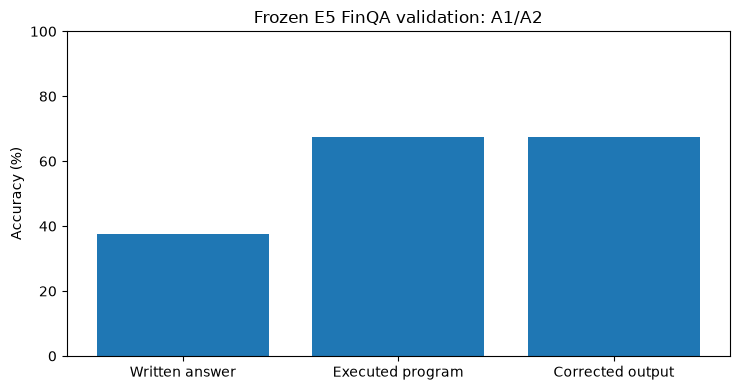

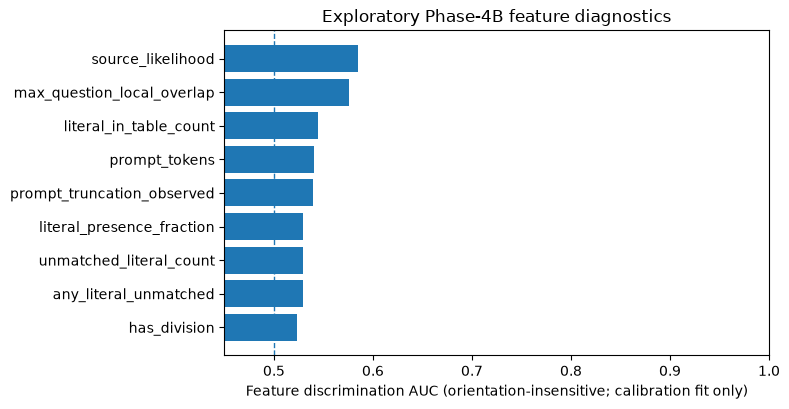

In [14]:
fig,ax=plt.subplots(figsize=(7.5,4))
ax.bar(['Written answer','Executed program','Corrected output'],
       [100*A1_A2['written_answer_accuracy'],100*A1_A2['executed_program_answer_accuracy'],100*A1_A2['corrected_output_accuracy']])
ax.set_ylabel('Accuracy (%)');ax.set_ylim(0,100)
ax.set_title('Frozen E5 FinQA validation: A1/A2')
fig.tight_layout();fig.savefig(ROOT/'plots/A1_A2_accuracy.png',dpi=170)
plt.show()

if len(A5_DF):
    sel=A5_DF.dropna(subset=['roc_auc_discrimination_symmetric']).head(9)
    fig,ax=plt.subplots(figsize=(8,4.2))
    ax.barh(sel['feature'].iloc[::-1],sel['roc_auc_discrimination_symmetric'].iloc[::-1])
    ax.axvline(0.5,ls='--',lw=1)
    ax.set_xlabel('Feature discrimination AUC (orientation-insensitive; calibration fit only)')
    ax.set_xlim(0.45,1.0);ax.set_title('Exploratory Phase-4B feature diagnostics')
    fig.tight_layout();fig.savefig(ROOT/'plots/A5_feature_discrimination.png',dpi=170)
    plt.show()

## 14. Manifest, student summary and self-contained review ZIP

In [15]:
manifest=[]
for path in sorted(ROOT.rglob('*')):
    if (path.is_file() and path.name not in ('Phase4A_Review_Package.zip',
                                                'artifact_inventory.json')):
        manifest.append({'relative_path':str(path.relative_to(ROOT)),
                         'sha256':file_sha(path),'size_bytes':path.stat().st_size})
dump_json(ROOT/'manifests/artifact_inventory.json',manifest)

summary=[
 '# Phase-4A Student Review Summary','',
 f'- Execution mode: **{RUN_MODE}**',
 f'- Core audit: **{READINESS["core_phase4a_status"]}**',
 f'- Validation: FinQA **{len(finqa)}**, FiQA **{len(fiqa)}**',
 f'- A1 written-answer accuracy: **{A1_A2["written_answer_accuracy"]:.2%}**',
 f'- A1 executed-program accuracy: **{A1_A2["executed_program_answer_accuracy"]:.2%}**',
 f'- A2 gain: **{A1_A2["execution_minus_written_gain_pp"]:.2f} percentage points**',
 f'- A3 structurally valid: **{A3["structural_valid_n"]}/{len(finqa)}**',
 f'- A4 any unmatched numbers: **{A4["unmatched_any_n"]}/{len(finqa)}**',
 f'- A4 evidence provenance: **{EVIDENCE_PROVENANCE}**',
 f'- Local new official executor: **{LIVE_EXEC["status"]}**',
 f'- E5 adapter bytes locally rechecked: **{ADAPTER_CHECK["status"]}**','',
 '## Interpretive cautions','',
 '- Valid execution corrects text arithmetic but does not certify the operations or source numbers.',
 '- A number appearing in a financial document does not establish that it supports a question.',
 '- Feature diagnostics use **calibration-fit only**; holdout labels are reserved for Phase-4B.',
 '- Feature JSONL files intentionally exclude targets; label JSONL files are separate.','',
 '## Next','',
 '- Phase-4B primary features: source likelihood, prompt length and truncation; hard reject unexecutable programs.',
 '- Phase-4B grounding extension: literal mismatch ONLY after original validation input recomputation.',
 '- Answer/execution agreement is an ablation-only signal (nearly no error discrimination in the fit subset).',
 '- Phase-4B: compare likelihood-only versus verifier-aware risk estimation on calibration-fit; run a single holdout assessment.',
 '- Phase-4C: compare full method to execution-only baseline; do not use protected tests before methodology freeze.',
]
(ROOT/'Phase4A_Student_Summary.md').write_text('\n'.join(summary),encoding='utf8')

# Recompute inventory after summary so it is present in package.
manifest=[]
for path in sorted(ROOT.rglob('*')):
    if (path.is_file() and path.name not in ('Phase4A_Review_Package.zip',
                                                'artifact_inventory.json')):
        manifest.append({'relative_path':str(path.relative_to(ROOT)),
                         'sha256':file_sha(path),'size_bytes':path.stat().st_size})
dump_json(ROOT/'manifests/artifact_inventory.json',manifest)
package_path=ROOT/'Phase4A_Review_Package.zip'
with zipfile.ZipFile(package_path,'w',compression=zipfile.ZIP_DEFLATED) as package:
    for p in sorted(ROOT.rglob('*')):
        if p.is_file() and p!=package_path:package.write(p,p.relative_to(ROOT))
print('Review package:',package_path,'bytes:',package_path.stat().st_size)
print('Phase4A:',READINESS['core_phase4a_status'])

Review package: /Users/krishpatel/Desktop/trust_fin/artifacts/phase4a/Phase4A_Review_Package.zip bytes: 174746
Phase4A: PASS


# Outputs students must share before Phase-4B

Send the **executed notebook** and `artifacts/phase4a/Phase4A_Review_Package.zip`. The review ZIP includes:

1. `manifests/phase4a_readiness.json` — main PASS/PENDING/FAIL decision.
2. `analysis/A1_A2_reconciliation.json` — written versus execution, correction outcomes.
3. `analysis/A3_program_structure_summary.json` and `A3_program_structure_cases.csv`.
4. `analysis/A4_operand_evidence_summary.json` and `A4_operand_evidence_cases.csv`.
5. `tables/A5_fit_feature_diagnostics.csv` and `A5_fit_subgroup_accuracy.csv`.
6. `phase4b_interface/phase4b_finqa_features.jsonl` and `phase4b_fiqa_features.jsonl`.
7. `labels/phase4b_finqa_labels.jsonl` and `phase4b_fiqa_labels.jsonl` — validation targets **separate from features**.
8. `phase4b_interface/phase4b_feature_policy.json` — frozen feature shortlist, leakage restrictions, and calibration split.
9. `manifests/input_fingerprints.json`, `live_evaluator_status.json`, `adapter_verification_status.json`, and `artifact_inventory.json`.
10. Two saved plots and student summary.

**Phase-4B should use only the features that have genuine inference-time parity.** If grounding was `CACHED_PHASE3_1_ONLY`, have the students rerun Phase-4A with `TRUSTFIN_PHASE2_VAL` to independently reconstruct those features before freezing any grounding-dependent calibrated risk model. The saved calibration holdout must remain untouched during feature selection.